# Module 01: MOT16 Environment Setup, Ground-Truth Parsing, and Baseline Detector Evaluation

**Course:** CS 5567 – Deep Learning  **Runtime:** GPU (T4, L4, or A100)

**Objective.** This notebook prepares the MOT16 benchmark for use in the project and verifies that the data pipeline is correct before any model is trained.

### Execution Pipeline
1. Configure the GPU runtime and mount Google Drive.
2. Download the MOT16 dataset once and store it on Drive.
3. Verify the directory structure of the training and test sequences.
4. Parse the ground-truth annotations.
5. Visualize the ground-truth bounding boxes to confirm that the parser is correct.
6. Run a pretrained YOLO detector on the same frames to establish a qualitative reference.


In [1]:
# 1. GPU check + Drive
import torch, subprocess
print('torch', torch.__version__, '| CUDA:', torch.cuda.is_available())
print(subprocess.run(['nvidia-smi','--query-gpu=name,memory.total','--format=csv,noheader'],capture_output=True,text=True).stdout)
from google.colab import drive
drive.mount('/content/drive')

torch 2.11.0+cu130 | CUDA: True
NVIDIA A100-SXM4-40GB, 40960 MiB

Mounted at /content/drive


In [2]:
%%bash
# 2. Download MOT16 into Drive ONCE (skips if already there)
mkdir -p /content/drive/MyDrive/MOT16_project && cd /content/drive/MyDrive/MOT16_project
if [ ! -d MOT16/train ]; then
  wget -q --show-progress https://motchallenge.net/data/MOT16.zip
  unzip -q MOT16.zip -d MOT16 && rm MOT16.zip
fi
ls MOT16

test
train


In [3]:
# 3. Install packages, copy data to fast local disk (Drive I/O is slow), verify layout
!pip -q install ultralytics boxmot motmetrics
!rm -rf /content/MOT16 && cp -r /content/drive/MyDrive/MOT16_project/MOT16 /content/MOT16
from pathlib import Path
ROOT = Path('/content/MOT16')
for split in ['train','test']:
    seqs = sorted(p.name for p in (ROOT/split).iterdir() if p.is_dir())
    print(split, len(seqs), seqs)
seq = ROOT/'train'/'MOT16-09'
print((seq/'seqinfo.ini').read_text())
print('frames:', len(list((seq/'img1').glob('*.jpg'))), '| gt exists:', (seq/'gt'/'gt.txt').exists())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 19.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 84.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 90.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.5/161.5 kB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 110.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 138.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.4/77.4 MB 35.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.7/310.7 kB 31.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 11.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency co

In [4]:
# 4. Parse ground truth
import numpy as np, pandas as pd

def parse_gt_file(file_path, pedestrians_only=True):
    """MOT16 gt.txt: frame,id,bb_left,bb_top,bb_width,bb_height,conf,class,visibility.
    conf=1 -> box is considered in evaluation; class 1 = pedestrian."""
    df = pd.read_csv(file_path, header=None,
                     names=['frame','id','x','y','w','h','conf','cls','vis'])
    if pedestrians_only:
        df = df[(df.cls == 1) & (df.conf == 1)]
    return df.reset_index(drop=True)

gt = parse_gt_file(seq/'gt'/'gt.txt')
print(gt.head())
print('rows', len(gt), '| frames', gt.frame.nunique(), '| unique pedestrian IDs', gt.id.nunique())
print(gt.groupby('frame').size().describe())  # pedestrians per frame

   frame  id    x    y    w    h  conf  cls  vis
0      1   1  260  450  102  262     1    1  1.0
1      2   1  262  449  102  263     1    1  1.0
2      3   1  264  449  102  263     1    1  1.0
3      4   1  266  448  102  264     1    1  1.0
4      5   1  268  448  102  264     1    1  1.0
rows 5257 | frames 525 | unique pedestrian IDs 25
count    525.000000
mean      10.013333
std        2.141425
min        6.000000
25%        8.000000
50%       10.000000
75%       12.000000
max       13.000000
dtype: float64


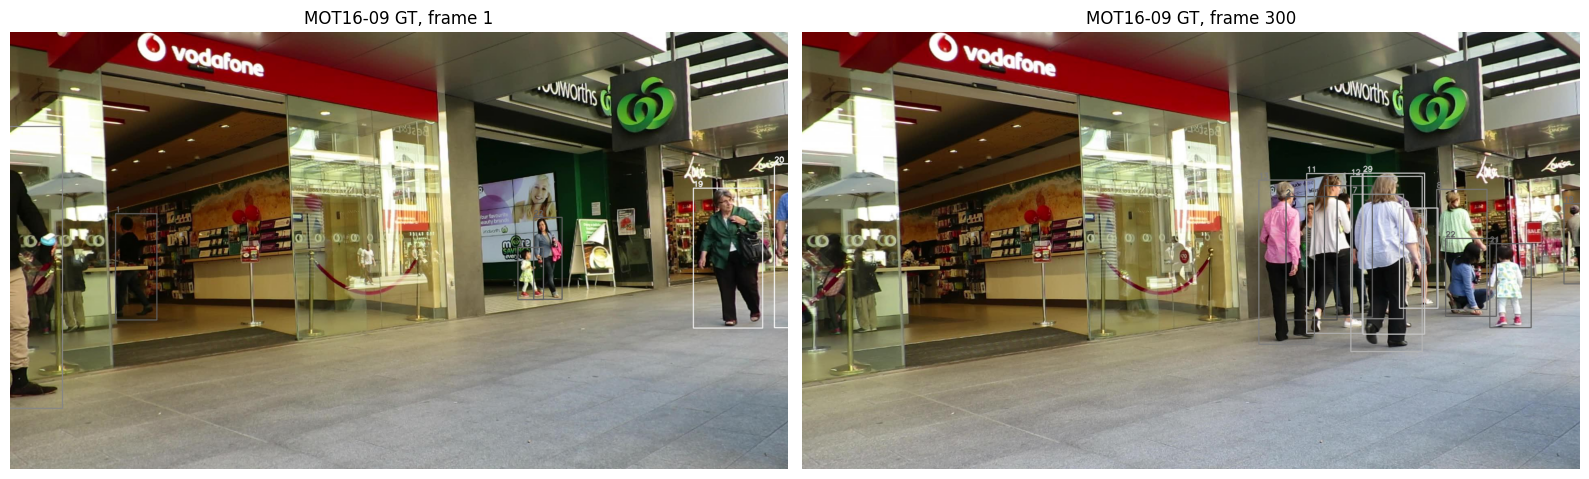

In [5]:
# 5. Draw GT boxes on a frame (sanity check: boxes must sit on people)
import cv2, random
import matplotlib.pyplot as plt

def draw_gt(seq, gt, frame_no):
    img = cv2.cvtColor(cv2.imread(str(seq/'img1'/f'{frame_no:06d}.jpg')), cv2.COLOR_BGR2RGB)
    for r in gt[gt.frame == frame_no].itertuples():
        color = tuple(random.Random(r.id).randrange(60, 255) for _ in range(3))  # same ID -> same color
        x, y, w, h = map(int, (r.x, r.y, r.w, r.h))
        cv2.rectangle(img, (x, y), (x + w, y + h), color, 2)
        cv2.putText(img, str(r.id), (x, max(y - 4, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return img

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, f in zip(ax, [1, 300]):
    a.imshow(draw_gt(seq, gt, f)); a.set_title(f'MOT16-09 GT, frame {f}'); a.axis('off')
plt.tight_layout(); plt.savefig('/content/drive/MyDrive/MOT16_project/gt_check.png', dpi=120); plt.show()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


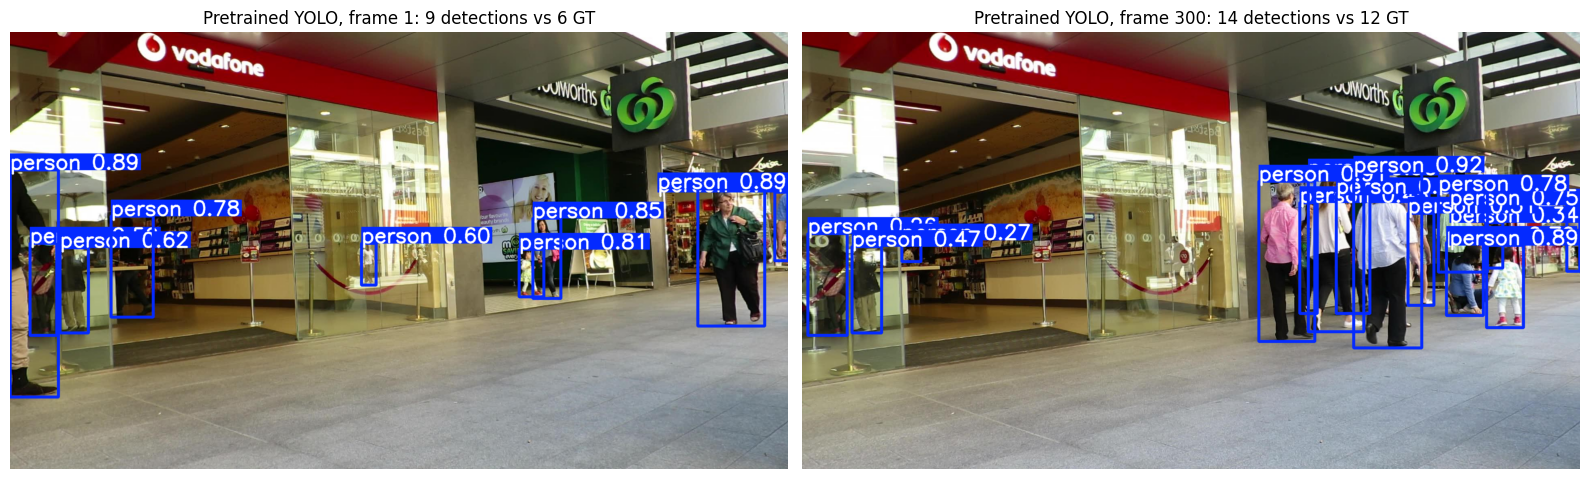

In [6]:
# 6. Pretrained YOLO on the same frames (class 0 = COCO 'person')
from ultralytics import YOLO
model = YOLO('yolo26m.pt')   # if this name is not found: try 'yolo11m.pt' and note it in the log
frames = [seq/'img1'/f'{f:06d}.jpg' for f in [1, 300]]
results = model.predict([str(p) for p in frames], classes=[0], conf=0.25, imgsz=960, verbose=False)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, r, f in zip(ax, results, [1, 300]):
    a.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    a.set_title(f'Pretrained YOLO, frame {f}: {len(r.boxes)} detections vs {int((gt.frame==f).sum())} GT'); a.axis('off')
plt.tight_layout(); plt.show()

## 7. Parameter-change experiment: `scale` augmentation

**Goal.** Show hands-on understanding of the detector by changing one training parameter and measuring its effect.

**Question.** Does random scale augmentation (`scale`) help detect pedestrians at many distances in MOT16-09?

**Design.**
- The only change is `scale`: 0.5 (our reference setting) versus 0.0 (off).
- Everything else is fixed: YOLO26m, 960 px, batch 8, seed 42, cosine LR, and the same sequence-level split (validation = MOT16-09).
- Each run trains for 10 epochs. The earlier 100-epoch run is not used for comparison, so both runs get equal training.
- Metrics: precision, recall, mAP@50 and mAP@50-95, with the person class only, on MOT16-09.

**Caveat.** Each setting is run once with a single seed. Small differences in mAP (under about 0.01) are within run-to-run noise and should not be read as a real effect. Multi-seed repeats are planned on HellBender.

**Output.** `results/augmentation_experiment.csv`


In [16]:
from ultralytics import YOLO
import pandas as pd

def run(name, **over):
    cfg = {**AUG, **over}
    m = YOLO(WEIGHTS)
    m.train(data=str(yaml_path), epochs=10, imgsz=IMGSZ, batch=BATCH, patience=10,
            project=str(RUNS), name=name, exist_ok=True, workers=2,
            cos_lr=True, seed=42, plots=False, **cfg)
    best = RUNS/name/'weights'/'best.pt'
    r = YOLO(str(best)).val(data=str(yaml_path), imgsz=IMGSZ, batch=BATCH, conf=0.001,
                            plots=False, project=str(RUNS), name=f'val_{name}', exist_ok=True)
    return dict(run=name, **over, P=r.box.mp, R=r.box.mr, mAP50=r.box.map50, mAP50_95=r.box.map)

rows = [run('exp_scale0.5', scale=0.5),      # reference setting
        run('exp_scale0.0', scale=0.0)]      # the one change: no scale augmentation
exp = pd.DataFrame(rows).round(4)
display(exp)
exp.to_csv(RESULTS/'augmentation_experiment.csv', index=False)


Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/yolo_mot16/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=exp_scale0.5, nbs=64, nms=None, opset=None, optimi

,run,scale,P,R,mAP50,mAP50_95
0,exp_scale0.5,0.5,0.9014,0.7481,0.8665,0.5872
1,exp_scale0.0,0.0,0.9475,0.7362,0.8642,0.5803


## 8. Qualitative comparison: pretrained vs fine-tuned detections

**Goal.** Show what the detector sees, not just the aggregate metrics.

**Method.**
- Take one frame from the middle of MOT16-09 (the held-out validation sequence).
- Run the COCO-pretrained YOLO26m (person class only) and our fine-tuned `best.pt` on the same frame.
- Use the same confidence threshold (0.25) and image size (960) for both, so the comparison is fair.

**How to read it.** Box counts on a single frame say little by themselves. Look for missed pedestrians, duplicate boxes, boxes on non-persons, and the confidence of boxes on partially occluded people. The mAP table in Section 5 remains the real quantitative comparison.

**Output.** `results/qualitative_pretrained_vs_finetuned.png`


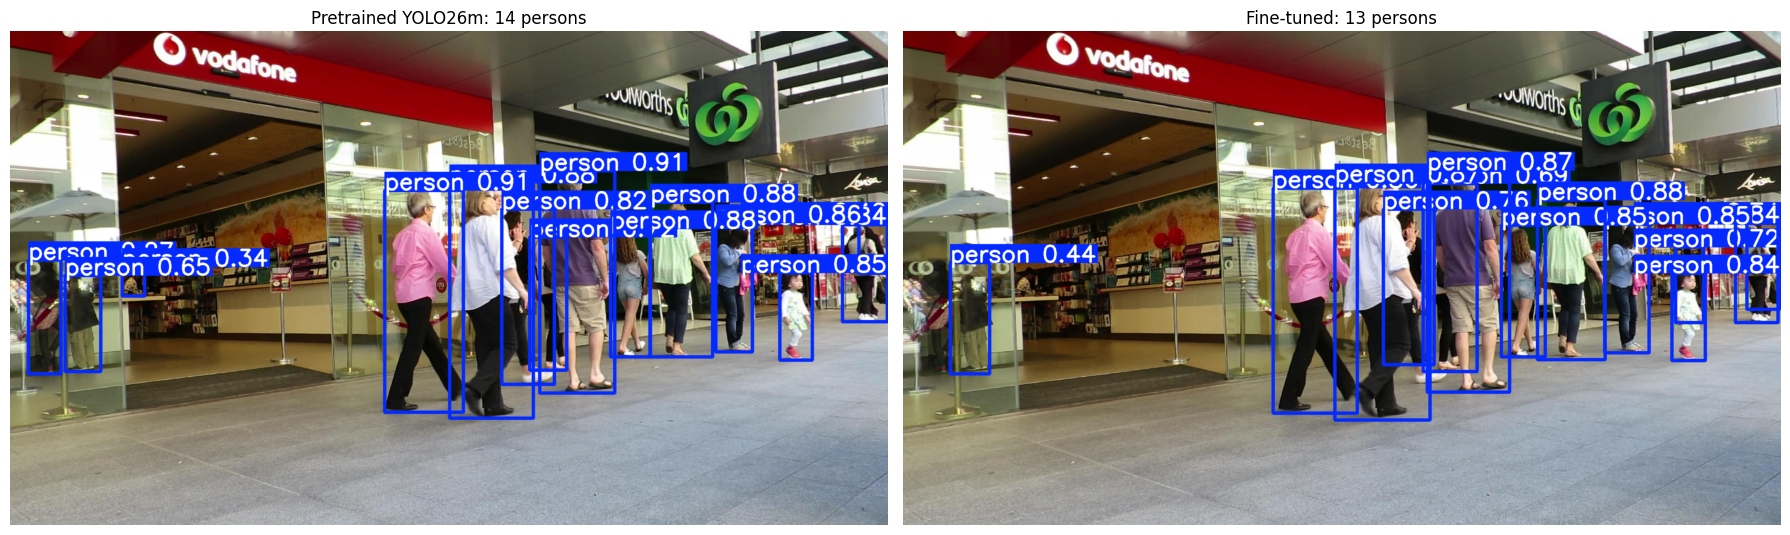

In [17]:
import matplotlib.pyplot as plt, cv2, glob
frames = sorted(glob.glob('/content/yolo_mot16/images/val/*'))
img = frames[len(frames)//2]            # a middle frame of MOT16-09
pre = YOLO(WEIGHTS)
ft  = YOLO(str(RUNS/RUN_NAME/'weights'/'best.pt'))

def draw(model, **kw):
    r = model.predict(img, imgsz=IMGSZ, conf=0.25, verbose=False, **kw)[0]
    return cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB), len(r.boxes)

a, na = draw(pre, classes=[0])
b, nb = draw(ft)
fig, ax = plt.subplots(1, 2, figsize=(18, 6))
ax[0].imshow(a); ax[0].set_title(f'Pretrained YOLO26m: {na} persons'); ax[0].axis('off')
ax[1].imshow(b); ax[1].set_title(f'Fine-tuned: {nb} persons'); ax[1].axis('off')
plt.tight_layout(); plt.savefig(RESULTS/'qualitative_pretrained_vs_finetuned.png', dpi=130); plt.show()


## 9. Reproducibility log: training settings and hardware

**Goal.** Record exactly how the detector was trained so the results can be reproduced and reported in the self-evaluation section of the final report.

**What is saved.**
- Model and weights: `yolo26m.pt`
- Epochs planned, image size (960), batch size (8), seed (42), cosine LR, early-stopping patience (10)
- Augmentation settings (`AUG`)
- Train/validation split by sequence (validation = MOT16-09)
- GPU model (NVIDIA A100-SXM4-40GB)

**Note.** `epochs_planned` is the configured value. The number of epochs actually run is the row count in `results.csv`; early stopping can end training sooner.

**Output.** `results/detector_training_config.json`


In [18]:
import json, torch
log = dict(model=WEIGHTS, epochs_planned=EPOCHS, imgsz=IMGSZ, batch=BATCH, aug=AUG,
           seed=42, cos_lr=True, patience=10, split='train: 02,04,05,10,11,13 | val: 09',
           gpu=torch.cuda.get_device_name(0))
json.dump(log, open(RESULTS/'detector_training_config.json', 'w'), indent=2)
print(log)


{'model': 'yolo26m.pt', 'epochs_planned': 30, 'imgsz': 960, 'batch': 8, 'aug': {'fliplr': 0.5, 'hsv_h': 0.015, 'hsv_s': 0.7, 'hsv_v': 0.4, 'scale': 0.5, 'degrees': 0.0, 'mosaic': 1.0}, 'seed': 42, 'cos_lr': True, 'patience': 10, 'split': 'train: 02,04,05,10,11,13 | val: 09', 'gpu': 'NVIDIA A100-SXM4-40GB'}
